In [2]:
pip install kagglehub


   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   ---------------------------------------- 0/2 [kagglesdk]
   -------------------- ------------------- 1/2 [kagglehub]
   -------------------- ------------------- 1/2 [kagglehub]
   -------------------- ------------------- 1/2 [kagglehub]
   -------------------- ------------------- 1/2 [kagglehub]
   -------------------- ------------------- 1/2 [kagglehub]
   -------------------- ---------------

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\jenim\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option('display.max_columns', None)

In [4]:
df = pd.read_csv(r'C:\Users\jenim\Desktop\DSML\Week2\D4\lab-eda-univariate\amz_uk_price_prediction_dataset.csv')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [9]:
df.shape

(2443651, 9)

In [10]:
display(df)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [5]:
num = df.select_dtypes(include='number')
cat = df.select_dtypes(exclude='number')

In [12]:
num.shape

(2443651, 5)

In [13]:
num.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 5 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   stars              float64
 2   reviews            int64  
 3   price              float64
 4   boughtInLastMonth  int64  
dtypes: float64(2), int64(3)
memory usage: 93.2 MB


In [14]:
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [6]:
num.duplicated().sum()

np.int64(0)

In [7]:
df.drop_duplicates()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [17]:
cat.shape

(2443651, 4)

In [18]:
cat

,asin,title,isBestSeller,category
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",True,Hi-Fi Speakers
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",False,Hi-Fi Speakers
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",False,Hi-Fi Speakers
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,False,Hi-Fi Speakers
...,...,...,...,...
2443646,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",False,Motorbike Clothing
2443647,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,False,Motorbike Clothing
2443648,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,False,Motorbike Clothing
2443649,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,False,Motorbike Clothing


In [19]:
cat.category.nunique()

296

Part 1: Understanding Product Categories
 1. Frequency Tables:

In [8]:
frequency = cat.category.value_counts()  #frequency generated
frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [9]:
proportion= round(cat.category.value_counts(normalize=True), 2)
proportion

category
Sports & Outdoors                         0.34
Beauty                                    0.01
Handmade Clothing, Shoes & Accessories    0.01
Bath & Body                               0.01
Birthday Gifts                            0.01
                                          ... 
Alexa Built-In Devices                    0.00
Motorbike Chassis                         0.00
Plugs                                     0.00
Smart Home Security & Lighting            0.00
Smart Speakers                            0.00
Name: proportion, Length: 296, dtype: float64

In [10]:
table = frequency.reset_index()
table.coulmns = ['category', 'count']
table

C:\Users\jenim\AppData\Local\Temp\ipykernel_28248\3631766336.py:2: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  table.coulmns = ['category', 'count']


,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Alexa Built-In Devices,107
292,Motorbike Chassis,107
293,Plugs,107
294,Smart Home Security & Lighting,104


Which are the top 5 most listed product categories?


In [11]:
top_5ordered = table.head(5)  #top 5 listed product catogories
top_5ordered

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


Visualizations: 
-Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

C:\Users\jenim\AppData\Local\Temp\ipykernel_28248\3498738204.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='category', y = 'count', data =top_5ordered, palette='magma')


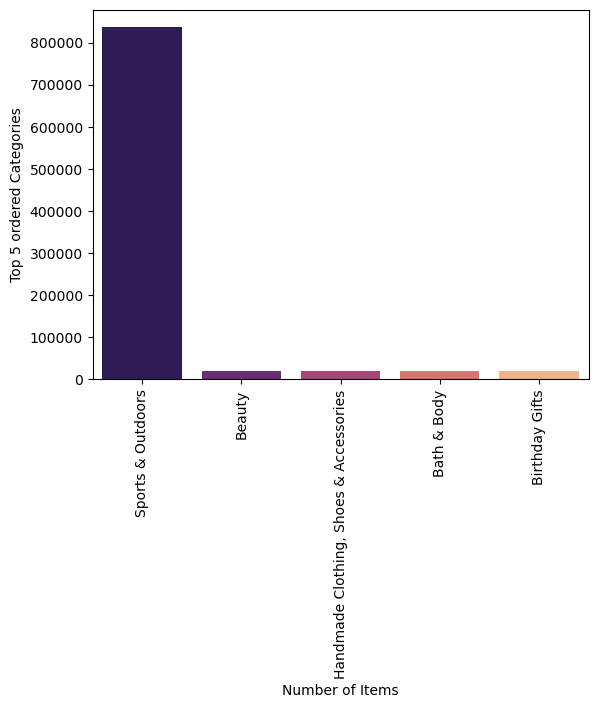

In [18]:
sns.barplot(x='category', y = 'count', data =top_5ordered, palette='magma')
plt.xlabel("Number of Items")
plt.ylabel("Top 5 ordered Categories")
plt.xticks(rotation=90)
plt.show()

For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

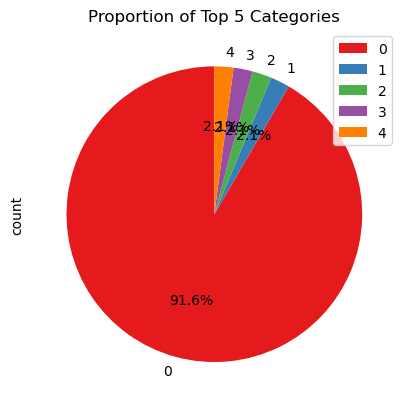

In [25]:
top_5ordered.plot(kind='pie', y='count', autopct='%1.1f%%' ,startangle=90, colors=sns.color_palette('Set1'))
plt.title("Proportion of Top 5 Categories")

plt.show()

In [26]:
#Sports and outdoor category dominates the listing

Part 2: Delving into Product Pricing --
 Measures of Centrality:

Calculate the mean, median, and mode for the price of products.
What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [60]:
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [63]:
round(float(num.price.mean()),2)

89.24

In [64]:
round(float(num.price.median()),2)

19.09

In [65]:
round(float(num.price.mode()),2)

C:\Users\jenim\AppData\Local\Temp\ipykernel_4512\359847181.py:1: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  round(float(num.price.mode()),2)


9.99

In [ ]:
#The average price point is 89.24. This is higher than the most common price(mode). 
# This means that most of the products are prices at lower values which inturn means that the price distribution is right-skewed.

Measures of Dispersion:

1. Determine the variance, standard deviation, range, and interquartile range for product price.
2. How varied are the product prices? Are there any indicators of a significant spread in prices?

In [69]:
variance = round(float(num.price.var()), 2)
variance

119445.49

In [70]:
std_dev = round(float(num.price.std()), 2)
std_dev

345.61

In [71]:
range_price = num.price.max() -num.price.min()
range_price


100000.0

In [75]:
interq_range = num.price.quantile(0.75) - num.price.quantile(0.25)
float(interq_range)

36.0

In [ ]:
#Variance gives us information abou the price spread i.e. how largely the product price varied. 
# The std_dev and the high range_price indicates a wider spread caused by high cost outliers.

Visualizations:

1. Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
2. Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [30]:
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


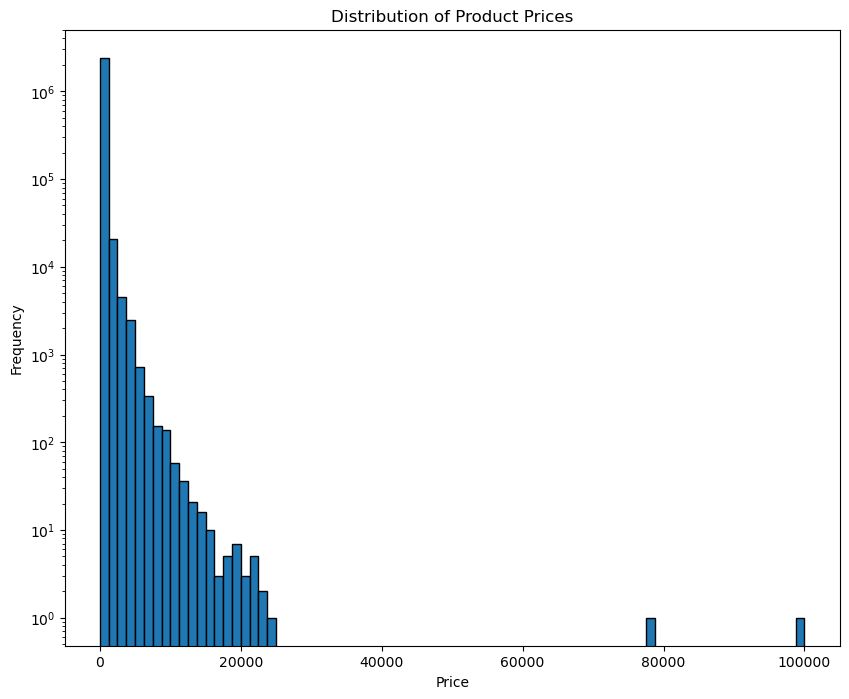

In [37]:
plt.figure(figsize=(10,8))
plt.hist(num.price, bins=80, edgecolor='black', log=True)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Distribution of Product Prices')
plt.show()

In [ ]:
#The histogram is difficult to read as it has a few extreme high priced items. This causes the majority of lower prices items to be compressed into the first few bins. 
#To fix this we can remove the outliers, and look into the main price range. I have used a log scale to fix this problem. 

In [41]:
num.price.describe()

count    2.443651e+06
mean     8.924381e+01
std      3.456089e+02
min      0.000000e+00
25%      9.990000e+00
50%      1.909000e+01
75%      4.599000e+01
max      1.000000e+05
Name: price, dtype: float64

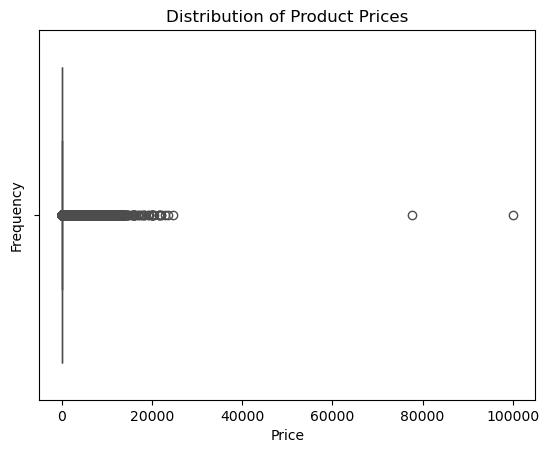

In [40]:
sns.boxplot(x=num.price, color= 'red')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.title('Distribution of Product Prices')
plt.show()

In [ ]:
#Due extreme high price of the 2 itmes, the box plot is compressed between the large number of low priced items that's why it is not visble in the boxplot.

Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

Measures of Centrality:

Calculate the mean, median, and mode for the rating of products.
How do customers generally rate products? Is there a common trend?


In [42]:
num

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443646,2828589,0.0,0,22.34,0
2443647,2828590,0.0,0,97.99,0
2443648,2828591,0.0,0,52.99,0
2443649,2828592,4.3,404,79.99,0


In [44]:
num.stars.describe()

count    2.443651e+06
mean     2.152836e+00
std      2.194865e+00
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      4.400000e+00
max      5.000000e+00
Name: stars, dtype: float64

In [46]:
float(num.stars.mean())

2.152836472966066

In [47]:
float(num.stars.median())

0.0

In [48]:
float(num.stars.mode())

C:\Users\jenim\AppData\Local\Temp\ipykernel_22368\2949374386.py:1: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  float(num.stars.mode())


0.0

Measures of Dispersion:

Determine the variance, standard deviation, and interquartile range for product rating.
Are the ratings consistent, or is there a wide variation in customer feedback?

In [49]:
float(num.stars.var())

4.81743402976196

In [50]:
float(num.stars.std())

2.1948653785054697

In [51]:
float(num.stars.quantile(0.75) - num.stars.quantile(0.25))

4.4

In [52]:
#For product rating that can only be scaled between 0 to 5 stars, the variance of 4.8, standard deviation of 2.2 indicates that the prodcut ratings vary higly.  
# The high variance indicate that the product rating is spread out with a lot of prodcuts rated 0 stars. 

Shape of the Distribution:

Calculate the skewness and kurtosis for the rating column.
Are the ratings normally distributed, or do they lean towards higher or lower values

In [56]:
skewness = float(num.stars.skew())
skewness

0.08120735761080881

In [58]:
kurtosis = float(num.stars.kurtosis())
kurtosis

-1.9260061280432994

In [62]:
#skewness >0 the rating distribution is positively skewed meaning most ratings are low with a longer tail on the right.
#Kurtosis <0 means there are fewer extreme outliers and the data is more spread out across the range.

Visualizations:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

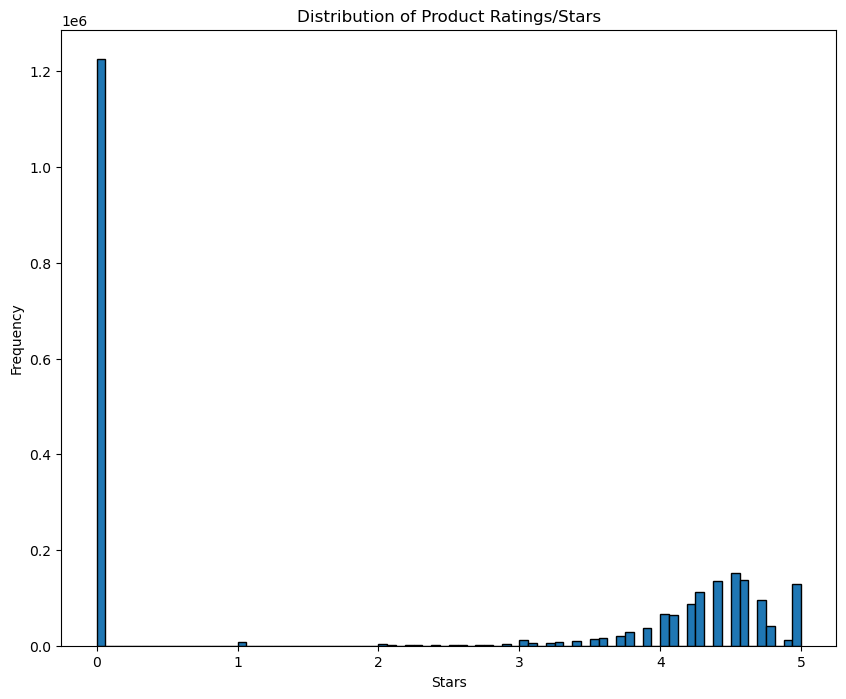

In [61]:
plt.figure(figsize=(10,8))
plt.hist(num.stars, bins=80, edgecolor='black')
plt.xlabel('Stars')
plt.ylabel('Frequency')
plt.title('Distribution of Product Ratings/Stars')
plt.show()

In [ ]:
#The histogram shows that most of the products were rated 0 stars.

Report: 
1. The highest number of products in the portfolio are in the Sports and Outdoor category.
2. The product portfolio contains mostly of inexpensive items. With the exception of only 2 items priced above 30000.
3. Most of the products have 0 stars, meaning they have not been rated. This means the unrated products may reduce customer trust.
4. Most products which were rated tend to have rating higer than 4 stars. Customer satisfaction for rated products seems higer.
5. The wide variation suggests inconsistent engagement across categories.
